# EDA — French Bakery Daily Sales

**Decision-maker:** the production manager (*responsable de production*) of a
single French bakery.
**Decision this has to support:** how much of each article to bake, every morning.

This notebook does not describe the dataset for its own sake. Every chart below
answers one question: *could this finding change a batch tomorrow morning?* The
findings that cannot are flagged as such, and they end up in the README section
"what we deliberately left out".

> **Language note.** The dataset belongs to a **French** bakery (dataset page:
> *"The dataset belongs to a French bakery"*), so the deployed Streamlit page is in
> French. This notebook, the code and these notes stay in English, because the
> course material, the library APIs and the reviewer are English. The README is
> bilingual.

## 1. Load, shape, dtypes

In [1]:
import sys
sys.path.insert(0, ".")

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from bakery import load_sales, sold_table, DATA_PATH

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9})

raw = pd.read_csv(DATA_PATH)
print("raw shape :", raw.shape)
print("columns   :", list(raw.columns))
raw.head()

raw shape : (234005, 7)
columns   : ['Unnamed: 0', 'date', 'time', 'ticket_number', 'article', 'Quantity', 'unit_price']


`Unnamed: 0` is just an exported row index and has to be dropped. The other six
columns are exactly the six variables listed on the dataset page.

`unit_price` is **French text** — `"0,90 €"`: decimal comma, euro sign, and a
narrow no-break space (`U+202F`). If it is not cleaned, the whole column stays a
string and every revenue figure is silently wrong. This is the single easiest
mistake to make with this dataset.

In [2]:
df = load_sales(DATA_PATH)
print("cleaned shape :", df.shape)
print(df.dtypes.to_string())
print()
print("price parsed  : %.4f %%" % (100 * df["price"].notna().mean()))
print("price range   : %.2f - %.2f" % (df["price"].min(), df["price"].max()))
print()
print("missing values per source column:")
print(df[["date", "time", "ticket_number", "article", "Quantity", "price"]]
      .isna().sum().to_string())

cleaned shape : (234005, 10)
date             datetime64[us]
time                        str
ticket_number             Int64
article                  string
Quantity                float64
unit_price                  str
price                   Float64
revenue                 Float64
minute                    int64
dow                       int32

price parsed  : 100.0000 %
price range   : 0.00 - 60.00

missing values per source column:
date             0
time             0
ticket_number    0
article          0
Quantity         0
price            0


After cleaning there are **zero missing values** and 100 % of prices parse. So the
problem with this dataset is never missingness — it is **definitions**: negative
quantities, closed days, a service line (`COUPE`), and catch-all buckets
(`DIVERS *`).

## 2. Period, open days, and the closed-day trap

In [3]:
cal = pd.date_range(df["date"].min(), df["date"].max())
open_days = pd.DatetimeIndex(sorted(df["date"].unique()))
closed = cal.difference(open_days)

print("span           :", df["date"].min().date(), "to", df["date"].max().date())
print("calendar days  :", len(cal))
print("open days      :", len(open_days))
print("closed days    :", len(closed))
print("closed by weekday (0=Mon):",
      dict(sorted(pd.Series([d.dayofweek for d in closed]).value_counts().items())))
print("observations per weekday :",
      dict(sorted(pd.Series([d.dayofweek for d in open_days]).value_counts().items())))

span           : 2021-01-02 to 2022-09-30
calendar days  : 637
open days      : 600
closed days    : 37
closed by weekday (0=Mon): {0: 3, 1: 2, 2: 29, 3: 2, 5: 1}
observations per weekday : {0: 88, 1: 89, 2: 62, 3: 89, 4: 91, 5: 90, 6: 91}


**What this changes for the dashboard.** 37 days with no rows are *not* days with
EUR 0 of sales — they are closures, and **29 of the 37 are Wednesdays** (the shop
closed every Wednesday from January to April 2021). Wednesday therefore has only
**62 observations** against 88-91 for every other weekday.

Two direct consequences: (1) the chart shows a gap and never plots a zero;
(2) any "all days pooled" average mixes different populations — which is why every
comparison in `bakery.py` happens **within a single weekday**.

In [4]:
print("total revenue : {:,.0f} EUR".format(df["revenue"].sum()))
print("rows          : {:,}".format(len(df)))
print("articles      :", df["article"].nunique())
print("tickets       : {:,}".format(df.groupby(["date", "ticket_number"]).ngroups))
print("negative qty  : {:,} rows / {:,.0f} units".format(
      (df["Quantity"] < 0).sum(), df.loc[df["Quantity"] < 0, "Quantity"].sum()))
print("rows per ticket, median : %.2f" %
      df.groupby(["date", "ticket_number"]).size().median())
print("tickets with >= 2 lines : %.1f %%" %
      (100 * (df.groupby(["date", "ticket_number"]).size() >= 2).mean()))

total revenue : 558,641 EUR
rows          : 234,005
articles      : 149
tickets       : 136,451
negative qty  : 1,295 rows / -2,201 units
rows per ticket, median : 1.00
tickets with >= 2 lines : 43.0 %


1,295 rows (0.55 %) carry a **negative** `Quantity`, for -2,201 units in total:
refunds and till corrections. They are not errors to fix, but they must be
**excluded** from the "last sale of the day" calculation — a late refund would push
the end-of-day time later and hide a genuine stock-out.

Note also that **43 % of tickets carry two or more lines**, so the number of rows is
not the number of customers: 234,005 lines are only 136,451 tickets.

## 3. Seasonality — why a "last 4 weeks" baseline fails

         open_days  avg_per_day
date                           
2021-12         26        733.0
2022-01         26        603.0
2022-02         24        734.0
2022-03         31        624.0
2022-04         30        822.0
2022-05         30        976.0
2022-06         30        843.0
2022-07         31       1503.0
2022-08         31       1737.0
2022-09         28        779.0


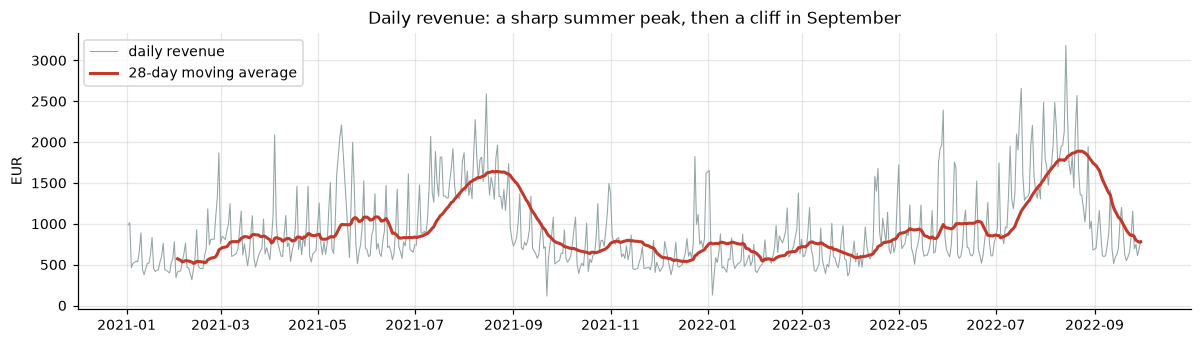

In [5]:
daily = df.groupby("date").agg(revenue=("revenue", "sum"),
                               lines=("revenue", "size"),
                               tickets=("ticket_number", "nunique"))

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(daily.index, daily["revenue"], lw=.7, color="#95a5a6", label="daily revenue")
ax.plot(daily["revenue"].rolling(28).mean(), lw=2, color="#c0392b",
        label="28-day moving average")
ax.set_title("Daily revenue: a sharp summer peak, then a cliff in September")
ax.set_ylabel("EUR")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

m = df.groupby(df["date"].dt.to_period("M")).agg(
    revenue=("revenue", "sum"), open_days=("date", "nunique"))
m["avg_per_day"] = m["revenue"] / m["open_days"]
print(m[["open_days", "avg_per_day"]].round(0).tail(10).to_string())

The summer peak is unambiguous: **EUR 1,737/day in August 2022** against
**EUR 779/day in September 2022** — revenue halves inside one month.

This is not a truncated export. In September 2022 the median last sale of the day is
still **18:54** (latest 19:00, normal closing) and the median number of articles on
sale is still **46** (37-60). The peak genuinely ended.

**Measured consequence.** A "last 4 same weekdays" baseline cannot cross that turn:

In [6]:
from bakery import YOY_MIN_DAYS, YOY_MAX_DAYS, REV_FALLBACK_OCC


def deltas(kind):
    out = []
    for dow_ in range(7):
        ds = [d for d in open_days if d.dayofweek == dow_]
        for i in range(4, len(ds)):
            d = ds[i]
            if kind == "yoy":
                prior = [x for x in ds[:i]
                         if YOY_MIN_DAYS <= (d - x).days <= YOY_MAX_DAYS]
                if not prior:
                    continue
            else:
                prior = ds[max(0, i - REV_FALLBACK_OCC):i]
            b = daily["revenue"].reindex(prior).mean()
            if b and b > 0:
                out.append((d, daily["revenue"][d] / b - 1))
    return pd.DataFrame(out, columns=["date", "delta"])


d4, dy = deltas("4wk"), deltas("yoy")
rows = []
for name, dd in (("last 4 same weekdays", d4), ("same weekday 1 year ago", dy)):
    sep = dd[dd["date"].dt.strftime("%Y-%m") == "2022-09"]
    rows.append({"baseline": name, "n": len(dd),
                 "std %": round(dd["delta"].std() * 100, 1),
                 "share < -20 % (all) %": round((dd["delta"] < -.2).mean() * 100, 1),
                 "n in 2022-09": len(sep),
                 "share < -20 % (2022-09) %": round((sep["delta"] < -.2).mean() * 100, 1),
                 "mean in 2022-09 %": round(sep["delta"].mean() * 100, 1)})
pd.DataFrame(rows).set_index("baseline")

Across the whole period the "4 weeks" baseline flags a drop larger than 20 % on
**27.1 %** of days. In September 2022 it flags **75.0 %** of days — while revenue is
actually **+15.8 % above** the same weeks last year.

The "same weekday one year ago" baseline flags **15.9 %** of days overall and only
**7.1 %** in September. That is the baseline `bakery.py` ships.

> A baseline that cries wolf every autumn is worse than no baseline at all.

## 4. Weekday structure — why the only useful filter is the weekday

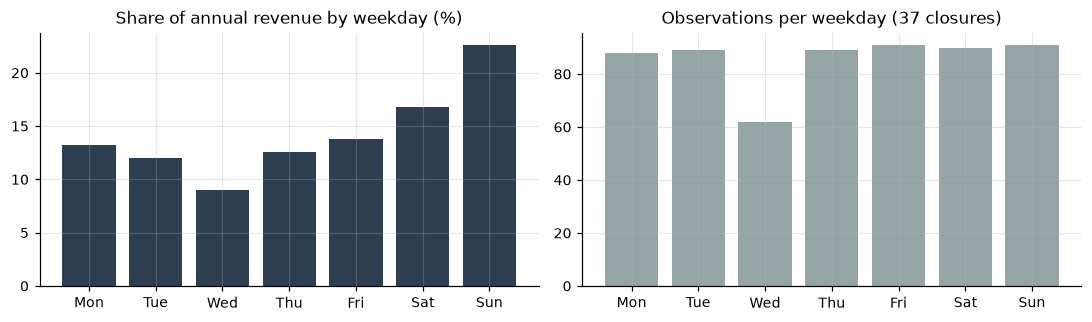

In [7]:
wr = df.groupby(df["date"].dt.dayofweek)["revenue"].sum()
share = wr / wr.sum() * 100
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
noc = [len([d for d in open_days if d.dayofweek == i]) for i in range(7)]

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].bar(names, share.values, color="#2c3e50")
axes[0].set_title("Share of annual revenue by weekday (%)")
axes[1].bar(names, noc, color="#95a5a6")
axes[1].set_title("Observations per weekday (37 closures)")
plt.tight_layout(); plt.show()

pd.DataFrame({"share_of_revenue_%": share.round(1), "observations": noc},
             index=pd.Index(names, name="weekday"))

Sunday carries **22.6 %** of annual revenue, Wednesday **9.0 %** — a factor of
**2.5**. No single "average day" number can serve both. Hence the one and only
filter on the page: **which weekday**.

Wednesday is also the only weekday that can run out of "one year ago" comparisons
(62 observations), so the code needs an explicit fallback.

## 5. Concentration — why we only track 20 articles

articles     : 149
top 1        : 25.9 %  (TRADITIONAL BAGUETTE)
top 5        : 48.1 %
top 20       : 75.6 %
top 50       : 92.5 %
remaining 129: 24.4 %


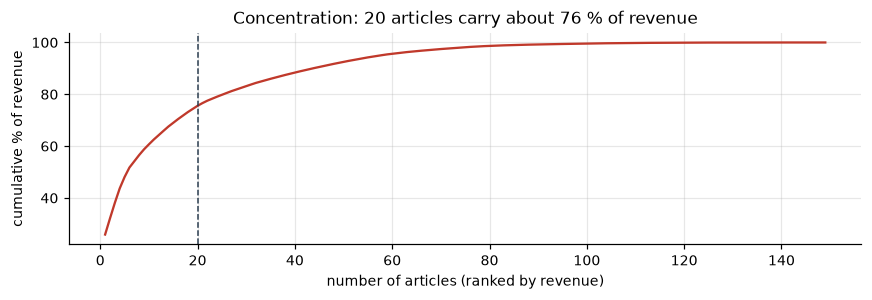

In [8]:
art = (df.groupby("article")
         .agg(revenue=("revenue", "sum"), units=("Quantity", "sum"),
              days=("date", "nunique"))
         .sort_values("revenue", ascending=False))
art["share_%"] = art["revenue"] / art["revenue"].sum() * 100
art["cum_%"] = art["share_%"].cumsum()

print("articles     :", len(art))
print("top 1        : %.1f %%  (%s)" % (art["share_%"].iloc[0], art.index[0]))
print("top 5        : %.1f %%" % art["cum_%"].iloc[4])
print("top 20       : %.1f %%" % art["cum_%"].iloc[19])
print("top 50       : %.1f %%" % art["cum_%"].iloc[49])
print("remaining 129: %.1f %%" % (100 - art["cum_%"].iloc[19]))

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(range(1, len(art) + 1), art["cum_%"].values, color="#c0392b")
ax.axvline(20, ls="--", lw=1, color="#2c3e50")
ax.set_xlabel("number of articles (ranked by revenue)")
ax.set_ylabel("cumulative % of revenue")
ax.set_title("Concentration: 20 articles carry about 76 % of revenue")
plt.tight_layout(); plt.show()

art.head(8)[["revenue", "share_%", "cum_%"]].round(1)

The traditional baguette alone is **25.9 %** of revenue (EUR 144,756 of 558,641).
The top 20 articles carry about 76 %; the remaining 129 share the last quarter.

That is the granularity argument: a production manager cannot adjust 149 batches,
but she can adjust twenty. Tracking the top 20 is a defensible decision backed by a
number, not a hunch.

## 6. Article sizes — and why the small ones are excluded

In [9]:
units = (df[df["Quantity"] > 0].groupby("article")["Quantity"].sum()
          / df.groupby("article")["date"].nunique())
art["units_per_day"] = units
art["revenue_per_day"] = art["revenue"] / art["days"]

bins = [0, 1, 3, 10, 30, 1e9]
labels = ["< 1/day", "1-3/day", "3-10/day", "10-30/day", ">= 30/day"]
art["band"] = pd.cut(art["units_per_day"], bins=bins, labels=labels)
tbl = art.groupby("band", observed=True).agg(
    articles=("revenue", "size"), revenue=("revenue", "sum"),
    median_units=("units_per_day", "median"))
tbl["share_of_revenue_%"] = (tbl["revenue"] / tbl["revenue"].sum() * 100).round(1)
print(tbl[["articles", "share_of_revenue_%", "median_units"]].round(2).to_string())
print()
print("median units/day : %.2f    p90 : %.2f" % (
      art["units_per_day"].median(), art["units_per_day"].quantile(.9)))

           articles  share_of_revenue_%  median_units
band                                                 
< 1/day          15                 0.0          1.00
1-3/day          72                10.0          1.98
3-10/day         53                42.1          4.28
10-30/day         3                 1.7         17.50
>= 30/day         6                46.2         40.88

median units/day : 2.69    p90 : 7.88


**87** of the 149 articles (15 below 1 unit/day plus 72 between 1 and 3) sell fewer
than 3 units a day and together carry only **10.0 %** of revenue. Six articles carry
**46.2 %**.

**What this killed.** An earlier version of the dashboard flagged "articles that
disappeared" (not sold for several weeks). It returned almost exclusively 1-3
units/day items — including `DEMI PAIN`, at **EUR 105 spread over its 131 selling
days, i.e. EUR 0.80/day**. Asking a baker to change a batch for EUR 0.80/day is not
a dashboard, it is noise. That indicator was deleted.

## 7. The stock-out signal — time of last sale

In [10]:
sold = sold_table(df).reset_index()
lm = sold.groupby("article")["last_minute"]

top20 = list(art.index[:20])
rows = []
for a in top20:
    v = lm.get_group(a)
    rows.append({"article": a, "median": v.median(), "p05": v.quantile(.05),
                 "before_11am_%": (v < 660).mean() * 100,
                 "units_per_day": art.loc[a, "units_per_day"]})
lasttbl = pd.DataFrame(rows).sort_values("median")
lasttbl["median_hhmm"] = lasttbl["median"].map(
    lambda x: "%02d:%02d" % (int(x) // 60, int(x) % 60))
print(lasttbl[["article", "median_hhmm", "before_11am_%", "units_per_day"]]
      .round(1).to_string(index=False))

             article median_hhmm  before_11am_%  units_per_day
             BRIOCHE       12:24           24.8            3.3
     GD KOUIGN AMANN       12:28           13.9            3.3
    SAND JB EMMENTAL       12:37           11.4            3.7
    GRAND FAR BRETON       12:41           11.1            3.7
    SANDWICH COMPLET       12:48            7.4            5.5
            TRAITEUR       12:50            7.6            4.7
    FORMULE SANDWICH       12:55            4.8            9.7
              ECLAIR       12:57            7.5            7.8
           VIK BREAD       13:37            7.1           10.0
          BOULE 400G       16:06            4.5            8.1
          TARTELETTE       16:10            4.4            9.2
             MOISSON       16:11            5.1            5.7
            CAMPAGNE       16:14            7.9            7.3
       SPECIAL BREAD       16:35            3.5            9.2
           CROISSANT       16:37            8.2        

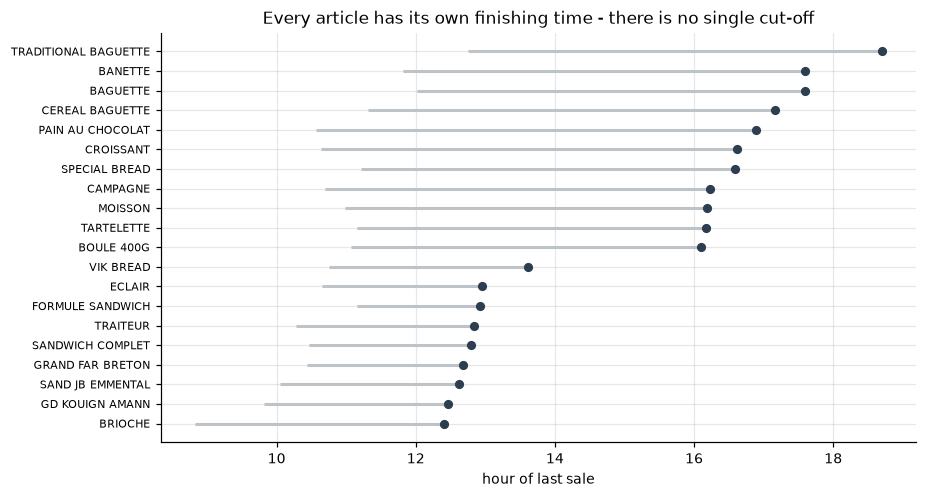

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
y = np.arange(len(lasttbl))
ax.hlines(y, lasttbl["p05"] / 60, lasttbl["median"] / 60, color="#bdc3c7", lw=2)
ax.plot(lasttbl["median"] / 60, y, "o", color="#2c3e50", ms=5)
ax.set_yticks(y)
ax.set_yticklabels(lasttbl["article"], fontsize=7)
ax.set_xlabel("hour of last sale")
ax.set_title("Every article has its own finishing time - there is no single cut-off")
plt.tight_layout(); plt.show()

The traditional baguette sells until a median **18:42** (baked in waves all day); the
brioche stops at **12:24** (one single morning batch). The data separates two
production modes by itself.

**Consequence:** a single threshold such as "sold out before 11:00 = stock-out" is
impossible. For the baguette it fires on 0.0 % of days; for the brioche on 24.8 %.
Such a rule would alert permanently on pastries and never on bread. The baseline must
be **each article's own median time**.

A second test shows why a second condition is also needed:

In [12]:
flags = {"n": 0, "gap>=60": 0, "gap>=60 & low qty": 0, "gap>=60 & normal qty": 0}
for a in top20:
    dates = sorted(sold.loc[sold["article"] == a, "date"].unique())
    for dow_ in range(7):
        ds = [d for d in dates if d.dayofweek == dow_]
        for i in range(12, len(ds)):
            hist = ds[i - 12:i]
            sub = sold[(sold["article"] == a) & (sold["date"].isin(hist))]
            base, baseq = sub["last_minute"].median(), sub["qty"].median()
            row = sold[(sold["article"] == a) & (sold["date"] == ds[i])]
            if row.empty or pd.isna(base) or not baseq:
                continue
            gap = base - row["last_minute"].iloc[0]
            ratio = row["qty"].iloc[0] / baseq
            flags["n"] += 1
            if gap >= 60:
                flags["gap>=60"] += 1
                if ratio < .5:
                    flags["gap>=60 & low qty"] += 1
                else:
                    flags["gap>=60 & normal qty"] += 1

print(flags)
print()
print("of the early finishes (>= 60 min), %.1f %% come from articles that sold"
      % (100 * flags["gap>=60 & low qty"] / flags["gap>=60"]))
print("less than 50 % of their normal volume - they were not sold out, they were")
print("simply selling badly that day.")

{'n': 8785, 'gap>=60': 2405, 'gap>=60 & low qty': 469, 'gap>=60 & normal qty': 1936}

of the early finishes (>= 60 min), 19.5 % come from articles that sold
less than 50 % of their normal volume - they were not sold out, they were
simply selling badly that day.


**19.5 %** of "early finishes" (469 of 2,405) come from articles that were not
selling that day at all. Example: `SPECIAL BREAD` on 2021-09-27 finished 217 minutes
early — but sold only **6.9 %** of its normal volume (1 unit against a normal 14.5).
That is not a stock-out; that is a day without customers.

Hence the final two-condition rule: **finished early (>= 30 min)** *and* **was still
selling (>= 80 % of normal volume)**. Applied to the top 20 across all 516 decisions,
that yields **3.56 flagged articles per day** (median 3, p90 7, max 15) and only
**8.9 %** of days with no signal at all. A short, correct list beats a long list to
argue with.

## 8. The under-production signal — why it must be share-normalised

In [13]:
pos = df[df["Quantity"] > 0]
day_units = pos.groupby("date")["Quantity"].sum()
art_units = pos.groupby(["date", "article"])["Quantity"].sum()

day = pd.Timestamp("2022-09-26")
ds = [d for d in open_days if d.dayofweek == 0]
i = ds.index(day)
hist = ds[i - 12:i]

hits_abs, hits_share = [], []
for a in top20:
    q = [art_units.get((d, a), 0) for d in hist]
    base_q = np.median([v for v in q if v > 0]) if any(v > 0 for v in q) else np.nan
    base_s = np.nanmedian([art_units.get((d, a), 0) / day_units.get(d, np.nan)
                           for d in hist])
    t = art_units.get((day, a), 0)
    if pd.notna(base_q) and base_q > 0 and t / base_q < .7:
        hits_abs.append(a)
    if pd.notna(base_s) and base_s > 0:
        sr = (t / day_units.get(day, np.nan)) / base_s
        if sr <= .6:
            hits_share.append((a, round(float(sr), 2)))

print("rule 'absolute units < 70 %% of normal': %d of 20 flagged" % len(hits_abs))
print("  ", hits_abs)
print()
print("rule 'share of shop units < 60 %% of its own median share': %d flagged"
      % len(hits_share))
print("  ", hits_share)
print()
prev_mon = [d for d in ds if d < day][-4:]
print("reference (mean of previous 4 Mondays) : %.0f EUR"
      % daily["revenue"].reindex(prev_mon).mean())
print("this Monday                            : %.0f EUR" % daily["revenue"][day])

rule 'absolute units < 70 % of normal': 15 of 20 flagged
   ['TRADITIONAL BAGUETTE', 'FORMULE SANDWICH', 'CROISSANT', 'PAIN AU CHOCOLAT', 'BANETTE', 'BAGUETTE', 'SPECIAL BREAD', 'GRAND FAR BRETON', 'TARTELETTE', 'CEREAL BAGUETTE', 'VIK BREAD', 'CAMPAGNE', 'GD KOUIGN AMANN', 'BOULE 400G', 'ECLAIR']

rule 'share of shop units < 60 % of its own median share': 4 flagged
   [('GRAND FAR BRETON', 0.0), ('VIK BREAD', 0.0), ('GD KOUIGN AMANN', 0.0), ('ECLAIR', 0.0)]

reference (mean of previous 4 Mondays) : 1038 EUR
this Monday                            : 694 EUR


On 26 September 2022 the **absolute-units** rule flags **15 articles out of 20** — the
page turns red and nobody reads it. The reason is the same as in section 3: the shop
is coming down from a EUR 1,737/day peak to EUR 694/day, well under the EUR 1,038/day
average of the previous four Mondays. *Everything* sells less.

The **share of shop units** rule (`article units / total units that day`, compared
with its own median share) is insensitive to that global level: it only flags
articles whose **composition** of the basket changed. On that day it flags **4**
articles — all of them at a share ratio of **0.0**, i.e. they genuinely did not sell.
That is the correct behaviour.

> Any article-level baseline must be normalised by the shop's own level that same
> day, otherwise a seasonal turn makes the whole page flash.

## 9. The basket metric we decided not to show

basket per ticket   : median 2.50  p10 1.15  p90 9.00
daily average basket: median 3.85  p10 3.24  p90 4.79
coefficient of variation of the daily average: 16.4 %


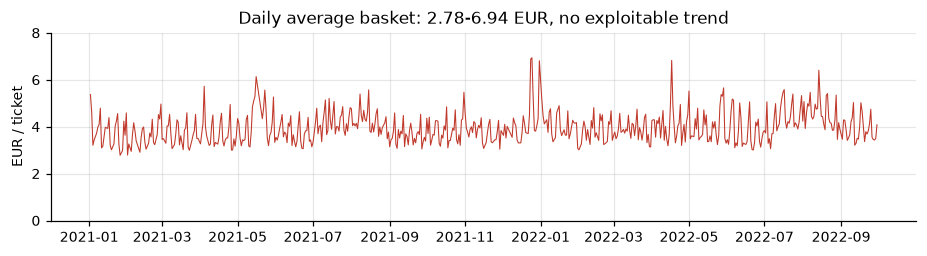

In [14]:
basket = df.groupby(["date", "ticket_number"])["revenue"].sum()
daily_basket = daily["revenue"] / daily["tickets"]

print("basket per ticket   : median %.2f  p10 %.2f  p90 %.2f"
      % (basket.median(), basket.quantile(.1), basket.quantile(.9)))
print("daily average basket: median %.2f  p10 %.2f  p90 %.2f"
      % (daily_basket.median(), daily_basket.quantile(.1), daily_basket.quantile(.9)))
print("coefficient of variation of the daily average: %.1f %%"
      % (100 * daily_basket.std() / daily_basket.mean()))

fig, ax = plt.subplots(figsize=(8.5, 2.4))
ax.plot(daily_basket.index, daily_basket, lw=.7, color="#c0392b")
ax.set_ylim(0, 8)
ax.set_title("Daily average basket: 2.78-6.94 EUR, no exploitable trend")
ax.set_ylabel("EUR / ticket")
plt.tight_layout(); plt.show()

The daily average basket has a median of **EUR 3.85**, a p10-p90 of
**EUR 3.24 - 4.79** and a coefficient of variation of **16.4 %**. It does not move
enough to change a single batch. It is the textbook example of a metric that is
interesting in EDA and useless for a decision, so it is explicitly cut from the page
(README, "what we deliberately left out").

## 10. What this dataset cannot answer

In [15]:
service = df[df["article"] == "COUPE"]
divers = df[df["article"].astype(str).str.startswith("DIVERS")]
print("COUPE (slicing service)  : %.0f EUR on %d rows"
      % (service["revenue"].sum(), len(service)))
print("DIVERS * (%d entries)     : %.0f EUR = %.2f %% of revenue"
      % (divers["article"].nunique(), divers["revenue"].sum(),
         100 * divers["revenue"].sum() / df["revenue"].sum()))
print()
print("distinct prices hidden under one article name (buckets, not SKUs):")
for a in ["TRAITEUR", "DIVERS PATISSERIE", "DIVERS VIENNOISERIE", "DIVERS BOULANGERIE"]:
    print("  %-22s %d distinct prices"
          % (a, df.loc[df["article"] == a, "price"].nunique()))
print()
print("columns the dataset does NOT have:")
print("  stock, quantity produced, unsold/waste, cost, margin, customer id,")
print("  discount flag, payment method, weather, shift, category")

COUPE (slicing service)  : 3526 EUR on 20470 rows
DIVERS * (6 entries)     : 10749 EUR = 1.92 % of revenue

distinct prices hidden under one article name (buckets, not SKUs):
  TRAITEUR               67 distinct prices
  DIVERS PATISSERIE      35 distinct prices
  DIVERS VIENNOISERIE    35 distinct prices
  DIVERS BOULANGERIE     32 distinct prices

columns the dataset does NOT have:
  stock, quantity produced, unsold/waste, cost, margin, customer id,
  discount flag, payment method, weather, shift, category


**The most important limitation of this dataset.** There is no stock, no quantity
produced, no unsold bread, no cost.

So this dashboard can say **"we ran out"** (an article stops selling mid-afternoon
while it was still selling), but it **cannot** say **"we baked too much"** — unsold
bread goes in the bin, and the bin is not in the till export. The "bake less" list is
therefore an **acknowledged proxy** (share of sales), and it is weaker evidence than
the "bake more" list. The README states this plainly.

Second point: `article` is free text with **no category column**, and the names are
coarse buckets rather than SKUs (`TRAITEUR` alone hides 67 distinct prices). That is
why the page carries **no chart by category**: rolling up to categories would destroy
exactly the granularity the manager can act on.

---

## Conclusion — what the EDA changed in the dashboard

| EDA finding | Product decision |
|---|---|
| 37 closures, 29 of them Wednesdays | Chart shows a gap, never a zero; weekday filter is mandatory |
| Summer peak then a -55 % cliff in one month | Baseline = same weekday one year ago, not the last 4 weeks |
| Sunday 22.6 % vs Wednesday 9.0 % | Exactly one filter: the weekday |
| Top 20 ~ 76 % of revenue | Decision scope = top 20 articles |
| 87 articles under 3 units/day = 10 % of revenue | The "disappeared articles" indicator was deleted |
| Every article has its own finishing time | Baseline = the article's own median, not a global cut-off |
| 19.5 % of early finishes = days without customers | Second condition: >= 80 % of normal volume |
| Absolute units -> 15 false positives out of 20 | Normalise by the article's share of shop units |
| Average basket almost flat (CV 16 %) | Cut from the page, documented in the README |
| No stock and no waste data | "Bake less" accepted as a weaker proxy |

**Next** -> the README (answers to Steps 1-4) and `app.py` (the page itself).